<a class="anchor" id="0"></a>
# **SVM para scoring de riesgo de incumplimiento (ejercicio)**

En este cuaderno se entrena un **clasificador SVM** para distinguir expedientes con **evento de incumplimiento a 12 meses** (`incumple_12m` = 1) frente a **no incumplimiento** (`incumple_12m` = 0), usando indicadores numéricos de **rentabilidad, volatilidad, forma de la distribución** y **liquidez/flujo** derivados de un fichero renombrado con **contexto financiero**.

**Nota didáctica:** los valores numéricos conservan la estructura del conjunto público de referencia **HTRU2** (detección de señales astrofísicas); aquí se **reinterpretan** como variables de un **ejercicio de riesgo de crédito** sin pretender ser estados contables reales.

Ejecute las celdas en orden (en Google Colab: **Entorno de ejecución → Ejecutar todo** tras subir `scoring_riesgo_credito_ejercicio.csv`).


*ML Finanzas (Clase 9) — ejercicio de scoring y máquinas de vectores de soporte.*


<a class="anchor" id="0.1"></a>
# **Índice**

1. [Introducción a las máquinas de vectores de soporte](#1)
2. [Intuición de las SVM](#2)
3. [Truco del núcleo (*kernel trick*)](#3)
4. [SVM en Scikit-Learn](#4)
5. [Descripción del conjunto de datos](#5)
6. [Importar librerías](#6)
7. [Cargar el conjunto de datos](#7)
8. [Análisis exploratorio](#8)
9. [Matriz de características y variable objetivo](#9)
10. [Partición entrenamiento / prueba](#10)
11. [Escalado de características](#11)
12. [SVM con hiperparámetros por defecto](#12)
13. [SVM con núcleo lineal](#13)
14. [SVM con núcleo polinomial](#14)
15. [SVM con núcleo sigmoide](#15)
16. [Matriz de confusión](#16)
17. [Métricas de clasificación](#17)
18. [Curva ROC y AUC](#18)
19. [Validación cruzada k-fold con mezcla (*shuffle*)](#19)
20. [Optimización de hiperparámetros con GridSearchCV](#20)
21. [Resultados y conclusiones](#21)
22. [Referencias](#22)


# **1. Introducción a las máquinas de vectores de soporte** <a class="anchor" id="1"></a>

[Índice](#0.1)

Las **máquinas de vectores de soporte** (SVM, por sus siglas en inglés) son algoritmos de aprendizaje supervisado para clasificación y regresión. Son muy utilizados en clasificación, regresión y detección de valores atípicos. Un clasificador SVM construye un modelo que asigna nuevas observaciones a una de las categorías; en el caso binario lineal puede verse como un clasificador lineal no probabilístico.

El algoritmo original fue desarrollado por Vladimir N. Vapnik y Alexey Ya. Chervonenkis en 1963. En 1992, Boser, Guyon y Vapnik propusieron clasificadores no lineales mediante el **truco del núcleo** aplicado a hiperplanos de margen máximo. La formulación estándar actual se debe en gran parte a Cortes y Vapnik (1993, publicada en 1995).

Las SVM permiten clasificación lineal y, mediante el **truco del núcleo**, proyectan implícitamente los datos a espacios de mayor dimensión donde una separación lineal puede ser más adecuada.




# **2. Intuición de las SVM** <a class="anchor" id="2"></a>

[Índice](#0.1)

### Hiperplano

Un hiperplano es una frontera de decisión que separa puntos con distintas etiquetas de clase. La SVM busca un hiperplano con **margen máximo** entre las clases. Ese hiperplano se denomina `hiperplano de margen máximo` y el clasificador lineal asociado, `clasificador de margen máximo`.

### Vectores de soporte

Los vectores de soporte son los puntos del entrenamiento más cercanos al hiperplano; definen la frontera y el margen.

### Margen

El margen es la separación entre las fronteras paralelas más cercanas a los datos de cada clase (distancia perpendicular al hiperplano). En las SVM se **maximiza** ese margen.

El siguiente diagrama ilustra estos conceptos.

### Margen en una SVM

![Margen en SVM](https://static.wixstatic.com/media/8f929f_7ecacdcf69d2450087cb4a898ef90837~mv2.png)

### Idea interna de la SVM

El objetivo es elegir el hiperplano que maximiza el margen respecto a los vectores de soporte. En dos pasos:

1. Generar hiperplanos que separen las clases lo mejor posible; entre muchos candidatos, interesa el que deje el mayor margen entre clases.

2. Elegir el hiperplano cuya distancia a los vectores de soporte a cada lado sea máxima. Si existe, es el **hiperplano de margen máximo** y el clasificador asociado es el **clasificador de margen máximo**.

### Hiperplano de margen máximo

![Hiperplano de margen máximo](https://static.packt-cdn.com/products/9781783555130/graphics/3547_03_07.jpg)

### Datos no linealmente separables

A veces los puntos están tan mezclados que no existe un hiperplano lineal que los separe. Entonces la SVM usa el **truco del núcleo** para mapear los datos a un espacio de mayor dimensión donde sí sea posible una separación (casi) lineal.

### Truco del núcleo: espacio de mayor dimensión

![Truco del núcleo](http://www.aionlinecourse.com/uploads/tutorials/2019/07/11_21_kernel_svm_3.png)



# **3. Truco del núcleo** <a class="anchor" id="3"></a>

[Índice](#0.1)

En la práctica, la SVM se implementa eligiendo un **núcleo** (*kernel*). El **truco del núcleo** consiste en usar una función que envía los datos a un espacio donde las clases resultan más separables. Así, problemas no linealmente separables en el espacio original pueden volverse linealmente separables en un espacio ampliado, lo que suele mejorar el clasificador.



Podemos definir conceptualmente una función de núcleo como sigue:

### Función de núcleo

![Función de núcleo](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTodZptqcRor0LGo8Qn7_kJB9n9BACMt6jgIPZ4C3g_rgh_uSRZLQ&s)

En el contexto de las SVM son habituales cuatro núcleos: **lineal**, **polinomial**, **RBF** (función de base radial, también llamado gaussiano) y **sigmoide**. A continuación se resumen.

## **3.1 Núcleo lineal**

En el núcleo lineal, la función de núcleo tiene forma lineal:

**Núcleo lineal: K(xᵢ, xⱼ) = xᵢᵀ xⱼ**

Se usa cuando los datos son (aproximadamente) linealmente separables. Es muy común y a menudo adecuado cuando hay muchas características. También es frecuente en clasificación de texto.

Entrenar con núcleo lineal suele ser más rápido: solo hay que ajustar en profundidad el parámetro de regularización **C**. Con otros núcleos suele ajustarse también **γ** (*gamma*), y una búsqueda en rejilla puede costar más.

### Núcleo lineal (ilustración)

![Núcleo lineal](https://scikit-learn.org/stable/_images/sphx_glr_plot_svm_kernels_thumb.png)

## **3.2 Núcleo polinomial**

El núcleo polinomial mide la similitud en un espacio de características polinómicas construido a partir de las variables originales; considera no solo los atributos sino ciertas interacciones entre muestras.

Para polinomios de grado d:

**Núcleo polinomial: K(xᵢ, xⱼ) = (γ xᵢᵀ xⱼ + r)ᵈ , γ > 0**

Es habitual en PLN; un grado frecuente es d = 2 (cuadrático), porque grados mayores tienden a sobreajustar en tareas de texto.

### Núcleo polinomial (ilustración)

![Núcleo polinomial](https://www.researchgate.net/profile/Cheng_Soon_Ong/publication/23442384/figure/fig12/AS:341444054274063@1458418014823/The-effect-of-the-degree-of-a-polynomial-kernel-The-polynomial-kernel-of-degree-1-leads.png)

## **3.3 Núcleo de función de base radial (RBF)**

El núcleo de función de base radial (RBF) es de propósito general. Se utiliza cuando no tenemos conocimiento previo sobre los datos. El núcleo RBF entre dos muestras x e y se define mediante la ecuación siguiente –


### Núcleo de función de base radial

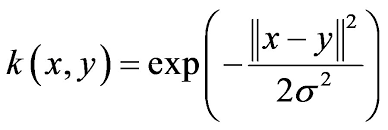

El siguiente diagrama muestra un ejemplo de clasificación SVM con núcleo RBF.

### Clasificación SVM con núcleo RBF

![Clasificación con núcleo RBF](https://www.researchgate.net/profile/Periklis_Gogas/publication/286180566/figure/fig5/AS:304327777374210@1449568804246/An-example-of-an-SVM-classification-using-the-RBF-kernel-The-two-classes-are-separated.png)

## **3.4 Núcleo sigmoide**

El núcleo sigmoide tiene origen en redes neuronales y puede interpretarse como un análogo. Tiene la forma:

**Núcleo sigmoide: k(x, y) = tanh(α xᵀy + c)**

Ilustración conceptual del núcleo sigmoide:

### Núcleo sigmoide

![Núcleo sigmoide](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTKeXbOIlniBXYwMYlEYLKPwZZg8vFU1wVm3RWMACjVcT4iBVDy&s)

# **4. SVM en Scikit-Learn** <a class="anchor" id="4"></a>

[Índice](#0.1)

Scikit-Learn ofrece herramientas listas para entrenar SVM. Para **clasificación**, las más relevantes son:

- **`LinearSVC`**: solo separación lineal (no se pasa `kernel`; está pensado para problemas lineales).

- **`SVC`** y **`NuSVC`**: clasificación con distintos núcleos. **`NuSVC`** controla el número de vectores de soporte mediante un parámetro ν. En **`SVC`** se suelen fijar `kernel`, `gamma` y `C` (entre otros). Por defecto, `kernel='rbf'`, pero puede usarse `'poly'`, `'linear'`, `'sigmoid'` o un núcleo personalizado.



# **5. Descripción del conjunto de datos** <a class="anchor" id="5"></a>

[Índice](#0.1)

Se trabaja con el archivo **`scoring_riesgo_credito_ejercicio.csv`**, filas **expedientes de crédito** (empresas u operaciones homogéneas) y columnas **indicadores calculados al momento de la concesión o revisión anual**.

La variable objetivo **`incumple_12m`** toma valor **1** si en la ventana siguiente se registra un **evento de incumplimiento** (mora material, reestructuración con pérdida, etc.) y **0** en caso contrario. La clase positiva (**incumplimiento**) suele ser **minoritaria**, lo que obliga a interpretar la exactitud junto con otras métricas.

### Atributos (8 predictores continuos + etiqueta)

Bloque **rentabilidad y riesgo de mercado** (cuatro primeras variables):

1. **`rend_medio`** — nivel medio de un indicador de rentabilidad normalizado.  
2. **`vol_rent`** — volatilidad del rendimiento (dispersión).  
3. **`curt_rent`** — exceso de curtosis: colas pesadas vs. normal.  
4. **`asim_rent`** — asimetría de la distribución del rendimiento.

Bloque **liquidez y flujo** (cuatro siguientes):

5. **`liq_medio`** — nivel medio de un ratio de liquidez / cobertura.  
6. **`vol_flujo`** — volatilidad asociada al flujo o a la cobertura de cargas financieras.  
7. **`curt_flujo`** — exceso de curtosis en el bloque liquidez-flujo.  
8. **`asim_flujo`** — asimetría en ese bloque.

9. **`incumple_12m`** — etiqueta binaria de incumplimiento a 12 meses.

Los números reproducibles coinciden con el dataset de referencia renombrado; el **significado económico** es una **ilustración pedagógica** para el curso.


# **6. Importar librerías** <a class="anchor" id="6"></a>

[Índice](#0.1)

En **Google Colab**, `numpy`, `pandas`, `matplotlib`, `seaborn` y `scikit-learn` suelen estar ya instalados. A continuación se importan las necesarias para el análisis.

In [ ]:
# Google Colab incluye NumPy, pandas, matplotlib, seaborn y scikit-learn.
# Si ejecuta este cuaderno fuera de Colab, instale las dependencias con pip según su entorno.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# --- Ruta al archivo CSV (ajuste si es necesario) ---
# Opción A: Subir el archivo con el menú Entorno de ejecución → Subir al almacenamiento de sesión
#           y dejarlo como /content/scoring_riesgo_credito_ejercicio.csv
# Opción B: from google.colab import files
#           uploaded = files.upload()
#           # Tras subir, suele quedar en /content/scoring_riesgo_credito_ejercicio.csv
# Opción C: Montar Google Drive y poner aquí la ruta al CSV en su Drive.

RUTA_CSV = "/content/scoring_riesgo_credito_ejercicio.csv"

if not os.path.isfile(RUTA_CSV):
    raise FileNotFoundError(
        "No se encuentra el archivo CSV. Descargue scoring_riesgo_credito_ejercicio.csv (misma carpeta Data del curso), "
        "suba la sesión de Colab o asigne la ruta correcta a RUTA_CSV."
    )


In [ ]:
import warnings

# Silenciar avisos no críticos durante la ejecución
warnings.filterwarnings('ignore')


# **7. Cargar el conjunto de datos** <a class="anchor" id="7"></a>

[Índice](#0.1)

In [ ]:
df = pd.read_csv(RUTA_CSV)


# **8. Análisis exploratorio** <a class="anchor" id="8"></a>

[Índice](#0.1)

Se exploran dimensiones, nombres de columnas, valores faltantes y distribuciones.

In [ ]:
# Dimensiones del DataFrame

df.shape


Hay **17.898** filas y **9** columnas.

In [ ]:
# Vista previa

df.head()


Hay **9** variables: **8** continuas y **1** discreta. La variable discreta es **`incumple_12m`**, la **variable objetivo** (riesgo de incumplimiento).

Se revisan los nombres de columna (el fichero del ejercicio ya trae encabezados cortos).

In [ ]:
# Nombres de columnas

col_names = df.columns
col_names


En este fichero los nombres vienen **sin espacios iniciales**; si en otro origen aparecieran, convendría usar `df.columns.str.strip()`.

In [ ]:
# Eliminar espacios en los nombres de columnas

df.columns = df.columns.str.strip()


Comprobación de `df.columns` tras aplicar `strip()` (no altera el fichero del ejercicio si ya está limpio).

In [ ]:
# Comprobar nombres

df.columns


El CSV del ejercicio incluye ya **nombres financieros cortos**. La siguiente celda **verifica** que coincidan con la lista esperada (equivalente al bloque de renombrado del cuaderno de referencia sobre el mismo conjunto numérico).

In [ ]:
# El CSV ya trae nombres financieros cortos; comprobar orden y etiquetas
esperadas = ['rend_medio', 'vol_rent', 'curt_rent', 'asim_rent',
             'liq_medio', 'vol_flujo', 'curt_flujo', 'asim_flujo', 'incumple_12m']
assert list(df.columns) == esperadas, list(df.columns)


In [ ]:
# Nombres tras el renombrado

df.columns


Las variables **`rend_medio` … `asim_flujo`** resumen rentabilidad, riesgo y liquidez. La objetivo es **`incumple_12m`**.

La variable objetivo es **`incumple_12m`**. Se revisa la distribución de frecuencias (clase minoritaria = incumplimientos).

In [ ]:
# Distribución de frecuencias de la variable objetivo

df['incumple_12m'].value_counts()


In [ ]:
# Porcentajes por clase

df['incumple_12m'].value_counts() / float(len(df))


Aproximadamente **90,84 %** de los expedientes son **no incumplimientos** (**0**) y **9,16 %** **incumplimientos** (**1**): hay **desbalance de clases**, típico en carteras de crédito sanas. Por ello no basta con mirar solo la exactitud.

In [ ]:
# Resumen del DataFrame

df.info()


No hay valores faltantes y todas las variables son numéricas.

### Valores faltantes por variable

In [ ]:
# Valores faltantes por columna

df.isnull().sum()


No hay valores faltantes.

### Resumen de variables numéricas

- Hay **9** variables numéricas.
- **8** predictoras continuas y **1** discreta (`incumple_12m`).
- No hay valores faltantes en el fichero de ejercicio.

### Valores atípicos en variables continuas

In [ ]:
# Estadísticos descriptivos (redondeados)

round(df.describe(), 2)


Los estadísticos sugieren **valores atípicos** en varias variables continuas.

Se usan diagramas de caja para visualizarlos.

In [ ]:
# Diagramas de caja para detectar valores atípicos

plt.figure(figsize=(24, 20))

plt.subplot(4, 2, 1)
fig = df.boxplot(column='rend_medio')
fig.set_title('')
fig.set_ylabel('rend_medio')

plt.subplot(4, 2, 2)
fig = df.boxplot(column='vol_rent')
fig.set_title('')
fig.set_ylabel('vol_rent')

plt.subplot(4, 2, 3)
fig = df.boxplot(column='curt_rent')
fig.set_title('')
fig.set_ylabel('curt_rent')

plt.subplot(4, 2, 4)
fig = df.boxplot(column='asim_rent')
fig.set_title('')
fig.set_ylabel('asim_rent')

plt.subplot(4, 2, 5)
fig = df.boxplot(column='liq_medio')
fig.set_title('')
fig.set_ylabel('liq_medio')

plt.subplot(4, 2, 6)
fig = df.boxplot(column='vol_flujo')
fig.set_title('')
fig.set_ylabel('vol_flujo')

plt.subplot(4, 2, 7)
fig = df.boxplot(column='curt_flujo')
fig.set_title('')
fig.set_ylabel('curt_flujo')

plt.subplot(4, 2, 8)
fig = df.boxplot(column='asim_flujo')
fig.set_title('')
fig.set_ylabel('asim_flujo')


Los diagramas de caja confirman la presencia de numerosos **valores atípicos** en estas variables.

### Valores atípicos y política de originación

En riesgo de crédito, **valores extremos** pueden corresponder a empresas muy apalancadas, picos de volatilidad o errores de datos. Las SVM con **margen suave** penalizan esos puntos mediante **C**: valores **altos de C** penalizan más los errores de clasificación en el entrenamiento y suelen usarse cuando se sospechan outliers pero se desea un límite claro al error.

### Distribución de los indicadores

Histogramas para ver si las variables son simétricas o sesgadas (común en ratios financieros).

In [ ]:
# Histogramas de las variables continuas

plt.figure(figsize=(24, 20))

plt.subplot(4, 2, 1)
fig = df['rend_medio'].hist(bins=20)
fig.set_xlabel('rend_medio')
fig.set_ylabel('Número de expedientes')

plt.subplot(4, 2, 2)
fig = df['vol_rent'].hist(bins=20)
fig.set_xlabel('vol_rent')
fig.set_ylabel('Número de expedientes')

plt.subplot(4, 2, 3)
fig = df['curt_rent'].hist(bins=20)
fig.set_xlabel('curt_rent')
fig.set_ylabel('Número de expedientes')

plt.subplot(4, 2, 4)
fig = df['asim_rent'].hist(bins=20)
fig.set_xlabel('asim_rent')
fig.set_ylabel('Número de expedientes')

plt.subplot(4, 2, 5)
fig = df['liq_medio'].hist(bins=20)
fig.set_xlabel('liq_medio')
fig.set_ylabel('Número de expedientes')

plt.subplot(4, 2, 6)
fig = df['vol_flujo'].hist(bins=20)
fig.set_xlabel('vol_flujo')
fig.set_ylabel('Número de expedientes')

plt.subplot(4, 2, 7)
fig = df['curt_flujo'].hist(bins=20)
fig.set_xlabel('curt_flujo')
fig.set_ylabel('Número de expedientes')

plt.subplot(4, 2, 8)
fig = df['asim_flujo'].hist(bins=20)
fig.set_xlabel('asim_flujo')
fig.set_ylabel('Número de expedientes')


Las ocho variables continuas muestran **asimetría**; en scoring suele aplicarse escalado y, en producción, transformaciones o tratamiento de outliers según la política del banco.

# **9. Matriz de características y variable objetivo** <a class="anchor" id="9"></a>

[Índice](#0.1)

In [ ]:
X = df.drop(['incumple_12m'], axis=1)

y = df['incumple_12m']


# **10. Partición en entrenamiento y prueba** <a class="anchor" id="10"></a>

[Índice](#0.1)

In [ ]:
# Partición entrenamiento / prueba (80 % - 20 %)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


In [ ]:
# Tamaños de los conjuntos

X_train.shape, X_test.shape


# **11. Escalado de características** <a class="anchor" id="11"></a>

[Índice](#0.1)

En modelos basados en distancias y SVM, conviene **estandarizar** los ratios para que magnitudes distintas no dominen el hiperplano.

In [ ]:
cols = X_train.columns


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)


In [ ]:
X_train = pd.DataFrame(X_train, columns=[cols])


In [ ]:
X_test = pd.DataFrame(X_test, columns=[cols])


In [ ]:
X_train.describe()


`X_train` y `X_test` están escalados (media ~0, varianza ~1 por columna) y listos para el modelo SVM.

# **12. SVM con hiperparámetros por defecto** <a class="anchor" id="12"></a>

[Índice](#0.1)

Por defecto en `SVC`: **C=1.0**, **kernel='rbf'** y **gamma** según configuración de scikit-learn (`'scale'` en versiones recientes).

In [ ]:
# Clasificador SVC con hiperparámetros por defecto
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svc = SVC()
svc.fit(X_train, y_train)
y_pred = svc.predict(X_test)

print('Exactitud del modelo (hiperparámetros por defecto): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


### SVM con núcleo RBF y C=100.0

Con datos financieros ruidosos, suele explorarse **C** más alto para reducir la influencia relativa de observaciones atípicas en el margen suave. Aquí se mantiene el experimento del cuaderno base con **RBF** y **C=100.0**.

In [ ]:
# Núcleo RBF y C=100
svc = SVC(C=100.0)
svc.fit(X_train, y_train)
y_pred = svc.predict(X_test)

print('Exactitud (RBF, C=100.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


Con **C=100.0** suele obtenerse mayor exactitud en prueba que con **C=1.0**. Se prueba también **C=1000.0**.

### SVM con núcleo RBF y C=1000.0


In [ ]:
# Núcleo RBF y C=1000
svc = SVC(C=1000.0)
svc.fit(X_train, y_train)
y_pred = svc.predict(X_test)

print('Exactitud (RBF, C=1000.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


En este conjunto, **C=1000.0** puede **reducir** la exactitud en prueba respecto a **C=100.0** (posible sobreajuste o interacción con el escalado).

# **13. SVM con núcleo lineal** <a class="anchor" id="13"></a>

[Índice](#0.1)

### SVM lineal con C=1.0

In [ ]:
# Núcleo lineal, C=1.0
linear_svc = SVC(kernel='linear', C=1.0)
linear_svc.fit(X_train, y_train)
y_pred_test = linear_svc.predict(X_test)

print('Exactitud (lineal, C=1.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred_test)))


### SVM lineal con C=100.0

In [ ]:
# Núcleo lineal, C=100.0
linear_svc100 = SVC(kernel='linear', C=100.0)
linear_svc100.fit(X_train, y_train)
y_pred = linear_svc100.predict(X_test)

print('Exactitud (lineal, C=100.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


### SVM lineal con C=1000.0

In [ ]:
# Núcleo lineal, C=1000.0
linear_svc1000 = SVC(kernel='linear', C=1000.0)
linear_svc1000.fit(X_train, y_train)
y_pred = linear_svc1000.predict(X_test)

print('Exactitud (lineal, C=1000.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


Con núcleo lineal, **C=100.0** y **C=1000.0** suelen mejorar respecto a **C=1.0** en este problema.

Aquí **`y_test`** son incumplimientos reales en el conjunto de prueba y **`y_pred_test`** las predicciones del SVM lineal con **C=1.0** (`linear_svc`).

### Comparar exactitud en entrenamiento y en prueba

Se comprueba si hay sobreajuste comparando el rendimiento en train y test.

In [ ]:
y_pred_train = linear_svc.predict(X_train)

y_pred_train


In [ ]:
print('Exactitud en entrenamiento: {0:0.4f}'.format(accuracy_score(y_train, y_pred_train)))


Las exactitudes en entrenamiento y prueba son **parecidas** (sin señal clara de sobreajuste fuerte).

### Sobreajuste y subajuste

In [ ]:
print('Puntuación en entrenamiento: {:.4f}'.format(linear_svc.score(X_train, y_train)))
print('Puntuación en prueba: {:.4f}'.format(linear_svc.score(X_test, y_test)))


Las puntuaciones en entrenamiento y prueba son coherentes; no parece un caso extremo de sobreajuste solo por esta comparación.


### Comparar con la exactitud nula

La **exactitud nula** es la que se obtendría prediciendo siempre la clase más frecuente (aquí, “no incumple”). Revise la distribución en prueba:

In [ ]:
# Distribución de clases en el conjunto de prueba

y_test.value_counts()


La mayoría de expedientes en **prueba** son **no incumplimientos** (3306 frente a 274 incumplimientos en el reparto fijo del ejercicio). La exactitud nula es aproximadamente 3306/(3306+274).

In [ ]:
# Exactitud nula (siempre predecir la clase mayoritaria)

null_accuracy = (3306 / (3306 + 274))

print('Exactitud nula: {0:0.4f}'.format(null_accuracy))


El modelo supera la exactitud nula: aporta capacidad predictiva frente a predecir siempre “sin incumplimiento”.

# **14. SVM con núcleo polinomial** <a class="anchor" id="14"></a>

[Índice](#0.1)

### Núcleo polinomial con C=1.0

In [ ]:
# Núcleo polinomial, C=1.0
poly_svc = SVC(kernel='poly', C=1.0)
poly_svc.fit(X_train, y_train)
y_pred = poly_svc.predict(X_test)

print('Exactitud (polinomial, C=1.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


### Núcleo polinomial con C=100.0

In [ ]:
# Núcleo polinomial, C=100.0
poly_svc100 = SVC(kernel='poly', C=100.0)
poly_svc100.fit(X_train, y_train)
y_pred = poly_svc100.predict(X_test)

print('Exactitud (polinomial, C=100.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


El núcleo polinomial rinde peor aquí; podría estar **sobreajustando** el entrenamiento.

# **15. SVM con núcleo sigmoide** <a class="anchor" id="15"></a>

[Índice](#0.1)

### Núcleo sigmoide con C=1.0

In [ ]:
# Núcleo sigmoide, C=1.0
sigmoid_svc = SVC(kernel='sigmoid', C=1.0)
sigmoid_svc.fit(X_train, y_train)
y_pred = sigmoid_svc.predict(X_test)

print('Exactitud (sigmoide, C=1.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


### Núcleo sigmoide con C=100.0

In [ ]:
# Núcleo sigmoide, C=100.0
sigmoid_svc100 = SVC(kernel='sigmoid', C=100.0)
sigmoid_svc100.fit(X_train, y_train)
y_pred = sigmoid_svc100.predict(X_test)

print('Exactitud (sigmoide, C=100.0): {0:0.4f}'.format(accuracy_score(y_test, y_pred)))


El núcleo sigmoide también rinde peor que RBF o lineal en este caso, de forma similar al polinomial.

### Comentarios

Con **núcleos RBF o lineal** y **C** adecuado se obtienen las mejores exactitudes de este flujo; ante **desbalance**, priorice **recall del incumplimiento**, **F1** y **AUC** frente a la sola exactitud.

# **16. Matriz de confusión** <a class="anchor" id="16"></a>

[Índice](#0.1)

La matriz de confusión resume **expedientes correctamente clasificados** frente a **falsos positivos** (alarma de incumplimiento sin que ocurra) y **falsos negativos** (incumplimiento no detectado). En riesgo de crédito, el coste de FN y FP no es simétrico.



In [ ]:
# Matriz de confusión
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_test)

print('Matriz de confusión\n\n', cm)

print('\nVerdaderos positivos (VP) = ', cm[0, 0])
print('\nVerdaderos negativos (VN) = ', cm[1, 1])
print('\nFalsos positivos (FP) = ', cm[0, 1])
print('\nFalsos negativos (FN) = ', cm[1, 0])


Los recuentos concretos dependen de su ejecución; interprete **VP/VN/FP/FN** en términos de **incumplimientos** predichos vs. reales.

In [ ]:
# Mapa de calor de la matriz de confusión

cm_matrix = pd.DataFrame(
    data=cm,
    columns=['Real incumple:1', 'Real no incumple:0'],
    index=['Predicho incumple:1', 'Predicho no incumple:0'],
)

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='YlGnBu')


# **17. Métricas de clasificación** <a class="anchor" id="17"></a>

[Índice](#0.1)

### Informe de clasificación

El **classification_report** de scikit-learn muestra **precisión**, **exhaustividad** (*recall*), **F1** y **soporte** por clase.

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_test))


### Exactitud de clasificación

In [ ]:
TP = cm[0, 0]
TN = cm[1, 1]
FP = cm[0, 1]
FN = cm[1, 0]


In [ ]:
# Exactitud de clasificación

classification_accuracy = (TP + TN) / float(TP + TN + FP + FN)

print('Exactitud de clasificación: {0:0.4f}'.format(classification_accuracy))


### Error de clasificación

In [ ]:
# Tasa de error de clasificación

classification_error = (FP + FN) / float(TP + TN + FP + FN)

print('Error de clasificación: {0:0.4f}'.format(classification_error))


### Precisión

Proporción de predicciones positivas correctas entre todas las predichas como positivas: VP / (VP + FP).

In [ ]:
# Precisión

precision = TP / float(TP + FP)

print('Precisión: {0:0.4f}'.format(precision))


### Exhaustividad (*recall*)

Proporción de positivos reales detectados: VP / (VP + FN). También se llama **sensibilidad**.

In [ ]:
recall = TP / float(TP + FN)

print('Exhaustividad (recall): {0:0.4f}'.format(recall))


### Tasa de verdaderos positivos

Coincide con la **exhaustividad** (*recall*).

In [ ]:
true_positive_rate = TP / float(TP + FN)

print('Tasa de verdaderos positivos: {0:0.4f}'.format(true_positive_rate))


### Tasa de falsos positivos

In [ ]:
false_positive_rate = FP / float(FP + TN)

print('Tasa de falsos positivos: {0:0.4f}'.format(false_positive_rate))


### Especificidad

VN / (VN + FP).

In [ ]:
specificity = TN / (TN + FP)

print('Especificidad: {0:0.4f}'.format(specificity))


### Puntuación F1

Media armónica de precisión y exhaustividad; equilibra ambos criterios. El valor va de 0 a 1.

### Soporte (*support*)

Número de ejemplos reales de cada clase en el conjunto usado (aquí, prueba).

# **18. Curva ROC y AUC** <a class="anchor" id="18"></a>

[Índice](#0.1)

### Curva ROC

La curva ROC contrasta la **tasa de verdaderos positivos** (sensibilidad al incumplimiento) con la **tasa de falsos positivos**. Es útil para elegir umbrales de **aprobación** o **revisión** en políticas de originación.

**Nota:** con predicciones duras de la SVM la curva puede verse simplificada; en producción suelen usarse **probabilidades calibradas** o **scores** continuos.



In [ ]:
# Curva ROC (nota: con predicciones discretas la curva puede verse simplificada)
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_pred_test)

plt.figure(figsize=(6, 4))

plt.plot(fpr, tpr, linewidth=2)
plt.plot([0, 1], [0, 1], 'k--')
plt.rcParams['font.size'] = 12

plt.title('Curva ROC — scoring de incumplimiento')
plt.xlabel('Tasa de falsos positivos (1 - especificidad)')
plt.ylabel('Tasa de verdaderos positivos (sensibilidad)')

plt.show()


La curva ROC ayuda a razonar sobre el equilibrio entre sensibilidad y especificidad según el umbral.

### AUC-ROC

El **área bajo la curva ROC (AUC)** resume el rendimiento: **1** sería un clasificador perfecto en ese gráfico; **0,5** correspondería a azar. Valores altos indican buena capacidad de separación entre clases.

In [ ]:
# AUC-ROC
from sklearn.metrics import roc_auc_score

ROC_AUC = roc_auc_score(y_test, y_pred_test)

print('AUC-ROC: {:.4f}'.format(ROC_AUC))


### Comentarios

- Un **AUC** alto indica buena capacidad de ordenar expedientes según riesgo de incumplimiento.
- En carteras reales conviene complementar con **calibración** y **estabilidad temporal** del modelo.

In [ ]:
# AUC-ROC con validación cruzada (entrenamiento)
from sklearn.model_selection import cross_val_score

Cross_validated_ROC_AUC = cross_val_score(linear_svc, X_train, y_train, cv=10, scoring='roc_auc').mean()

print('AUC-ROC (validación cruzada, media): {:.4f}'.format(Cross_validated_ROC_AUC))


# **19. Validación cruzada k-fold con mezcla** <a class="anchor" id="19"></a>

[Índice](#0.1)

La validación cruzada estima la estabilidad del score fuera de la muestra. Con **clases desbalanceadas**, **`StratifiedKFold`** mantiene la proporción de incumplimientos en cada pliegue; el código siguiente replica el **KFold con shuffle** del tutorial para comparar.

### Validación cruzada con núcleo lineal (`KFold`, shuffle)

In [ ]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=0)

linear_svc = SVC(kernel='linear')

linear_scores = cross_val_score(linear_svc, X, y, cv=kfold)


In [ ]:
# Puntuaciones de validación cruzada (núcleo lineal)

print('Puntuaciones de validación cruzada (lineal):\n\n{}'.format(linear_scores))


In [ ]:
# Media de las puntuaciones (lineal)

print('Media (lineal): {:.4f}'.format(linear_scores.mean()))


### Validación cruzada con núcleo RBF

In [ ]:
rbf_svc = SVC(kernel='rbf')

rbf_scores = cross_val_score(rbf_svc, X, y, cv=kfold)


In [ ]:
# Puntuaciones de validación cruzada (RBF)

print('Puntuaciones de validación cruzada (RBF):\n\n{}'.format(rbf_scores))


In [ ]:
# Media de las puntuaciones (RBF)

print('Media (RBF): {:.4f}'.format(rbf_scores.mean()))


La validación cruzada puede dar una media ligeramente distinta a un único split; valore **AUC** y **F1** en el segmento de incumplimientos.

# **20. Optimización de hiperparámetros con GridSearchCV** <a class="anchor" id="20"></a>

[Índice](#0.1)

In [ ]:
# Búsqueda en rejilla de hiperparámetros
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

svc = SVC()

parameters = [
    {'C': [1, 10, 100, 1000], 'kernel': ['linear']},
    {
        'C': [1, 10, 100, 1000],
        'kernel': ['rbf'],
        'gamma': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    },
    {
        'C': [1, 10, 100, 1000],
        'kernel': ['poly'],
        'degree': [2, 3, 4],
        'gamma': [0.01, 0.02, 0.03, 0.04, 0.05],
    },
]

grid_search = GridSearchCV(
    estimator=svc,
    param_grid=parameters,
    scoring='accuracy',
    cv=5,
    verbose=0,
)

grid_search.fit(X_train, y_train)


In [ ]:
# Mejor modelo según GridSearchCV

print('Mejor puntuación (validación cruzada en entrenamiento): {:.4f}\n\n'.format(grid_search.best_score_))

print('Mejores hiperparámetros:', '\n\n', grid_search.best_params_)

print('\n\nMejor estimador:', '\n\n', grid_search.best_estimator_)


In [ ]:
# Exactitud del mejor estimador en el conjunto de prueba

print('Exactitud en prueba (mejor modelo): {0:0.4f}'.format(grid_search.score(X_test, y_test)))


### Comentarios

- La exactitud en el conjunto de prueba del modelo afinado puede ser muy cercana a la del modelo inicial.
- **GridSearchCV** ayuda a explorar combinaciones de `C`, `kernel`, `gamma`, etc.
- No confunda **`best_score_`** (media de validación cruzada en entrenamiento) con **`score(X_test, y_test)`** (rendimiento en el conjunto de prueba reservado).

# **21. Resultados y conclusiones** <a class="anchor" id="21"></a>

[Índice](#0.1)

1. Los **outliers** en ratios financieros interactúan con **C** y el núcleo; conviene sensibilizar el modelo y la política de datos.

2. Los mejores resultados de exactitud en este cuaderno suelen alcanzarse con **RBF** o **lineal** y **C** alto; la **exactitud sola** puede ocultar un mal seguimiento del **incumplimiento** minoritario.

3. Un **AUC-ROC** alto sugiere buen poder de **ordenación** por riesgo.

4. Use **validación estratificada** si implementa el modelo en un motor de scoring real.

5. **GridSearchCV** ayuda a afinar hiperparámetros; valide siempre en **prueba** y, idealmente, en **ventanas temporales** (no mostrado aquí).



# **22. Referencias** <a class="anchor" id="22"></a>

[Índice](#0.1)

1. *Hands-On Machine Learning* — Aurélien Géron  
2. *Introduction to Machine Learning with Python* — Müller y Guido  
3. Documentación scikit-learn: `SVC`, `GridSearchCV`, métricas.  
4. Literatura sobre **scoring crediticio**, **Basilea**, **IFRS 9** (expected credit loss) para contextualizar el uso de modelos en banca.



Fin del cuaderno. Compruebe que ha subido **`scoring_riesgo_credito_ejercicio.csv`** y que **`RUTA_CSV`** apunta al archivo en su sesión de Colab.

**Disclaimer:** ejercicio académico; los datos son una **reinterpretación** del conjunto HTRU2 con nombres financieros.


[Volver al inicio](#0)